# 1. Dataset description

Przedstawiony zbiór zawiera zapisy EEG w systemie międzynarodowym 10/20 z badań podczas wykonywania zadania arytmetycznego (seryjne odejmowanie) oraz odpowiadające im nagrania referencyjne w spoczynku. Zbiór pochodzi z PhysioNet i nadaje się do analiz dynamiki mózgu przy obciążeniu poznawczym.

Źródło: Zyma I. et al. (2019), "Electroencephalograms during Mental Arithmetic Task Performance", Data / PhysioNet


## Uwaga - środowisko

- Wybierz kernel `Python (in-ynierka)` w Jupyter / VS Code (ten kernel został zarejestrowany w projekcie).
- Jeśli kernel nie ma zainstalowanych zależności, odpal w komórce poniżej (używa `%pip`, co instaluje w aktywnym kernelu):


## 2. Szybkie importy i konfiguracja

Tutaj importujemy moduły z pakietu `eegmat` (zawartość notebooka została przeniesiona do modułów).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import mne

from eegmat.io import load_all, read_one, parse_fname
from eegmat.preprocess import tidy, set_montage
from eegmat.dataset import make_dataset

mne.set_log_level('WARNING')

## 3. Lokalizacja danych

Skanujemy typowe ścieżki projektu aby znaleźć katalog z plikami EDF (jeśli masz dane w innym miejscu, zaktualizuj `candidates`).


In [2]:
def find_data_dir():
    candidates = [
        Path('datasets/physionet.org/files/eegmat/1.0.0'),
        Path('physionet.org/files/eegmat/1.0.0'),
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(f'No data dir found. Checked: {candidates}')

DATA_DIR = find_data_dir()
print('DATA_DIR =', DATA_DIR)

DATA_DIR = physionet.org/files/eegmat/1.0.0


## 4. (Opcjonalnie) wczytaj metadane `subject-info.csv` jeśli istnieją


In [3]:
info_path = DATA_DIR / 'subject-info.csv'
if info_path.exists():
    info = pd.read_csv(info_path)
    display(info.head())
else:
    print('Brak subject-info.csv w:', info_path)

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality
0,Subject00,21,F,2011,9.70,0
1,Subject01,18,F,2011,29.35,1
2,Subject02,19,F,2012,12.88,1
3,Subject03,17,F,2010,31.00,1
4,Subject04,17,F,2010,8.60,0


## 5. Wczytanie jednego pliku (szybkie sprawdzenie)

Pokazujemy podstawowe info o surowym nagraniu.


In [4]:
# Wczytaj przykładowy plik (Subject00_1.edf)
sample = read_one(DATA_DIR / 'Subject00_1.edf', preload=True)
sample = tidy(sample)
sample = set_montage(sample)
print(sample.info)
print('Channels:', sample.ch_names)
print('Sampling freq:', sample.info['sfreq'], 'Hz')
print('Duration (s):', sample.times[-1])

<Info | 9 non-empty values
 bads: []
 ch_names: Fp1, Fp2, F3, F4, F7, F8, T7, T8, C3, C4, P7, P8, P3, P4, O1, ...
 chs: 19 EEG, 1 misc, 1 ECG
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.5 Hz
 lowpass: 45.0 Hz
 meas_date: 2011-01-01 00:00:00 UTC
 nchan: 21
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: 0, sex: 1, last_name: Subject0, birthday: 1990-01-01>
>
Channels: ['Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'T7', 'T8', 'C3', 'C4', 'P7', 'P8', 'P3', 'P4', 'O1', 'O2', 'Fz', 'Cz', 'Pz', 'A2-A1', 'ECG ECG']
Sampling freq: 500.0 Hz
Duration (s): 181.998


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


## 6. Zbuduj dataset (epoki) i sprawdź rozmiary

Funkcja `make_dataset(records)` tworzy X, y, groups tak jak w poprzednim notebooku.


In [5]:
records = load_all(DATA_DIR, preload=False)  # preload można zmienić dla pamięciochłonnych operacji
print('loaded records:', len(records))
X, y, groups = make_dataset(records, epoch_len=4.0)
print('X shape:', X.shape)  # (n_epochs, n_channels, n_samples)
if y.size:
    print('y counts:', dict(zip(*np.unique(y, return_counts=True))))
else:
    print('y counts: empty')

loaded records: 67


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)
/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel

X shape: (1969, 19, 2000)
y counts: {np.int64(0): np.int64(1459), np.int64(1): np.int64(510)}


## 7. Przykład: wykres PSD jednego nagrania

Uwaga: interaktywne wykresy mogą wymagać, żeby kernel miał dostęp do GUI (w VS Code wybierz odpowiedni backend matplotlib lub zapisz wykres).


/Users/gsk/documents/projects/in-ynierka/eegmat/preprocess.py:25: RuntimeWarning: The unit for channel(s) A2-A1 has changed from V to NA.
  raw.set_channel_types(remap)


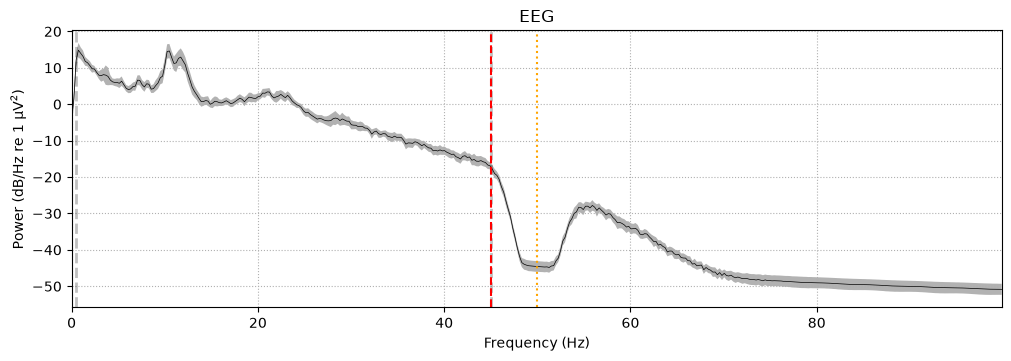

In [6]:
import matplotlib.pyplot as plt

raw_chk = set_montage(tidy(read_one(DATA_DIR / 'Subject00_1.edf', preload=True).copy()))
psd = raw_chk.compute_psd(picks='eeg', fmax=100)
ax = psd.plot(average=True, show=False)
plt.axvline(45, ls='--', c='r')
plt.axvline(50, ls=':', c='orange')
plt.show()

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=group_col, y=value_col, data=df, order=order, palette=palette)


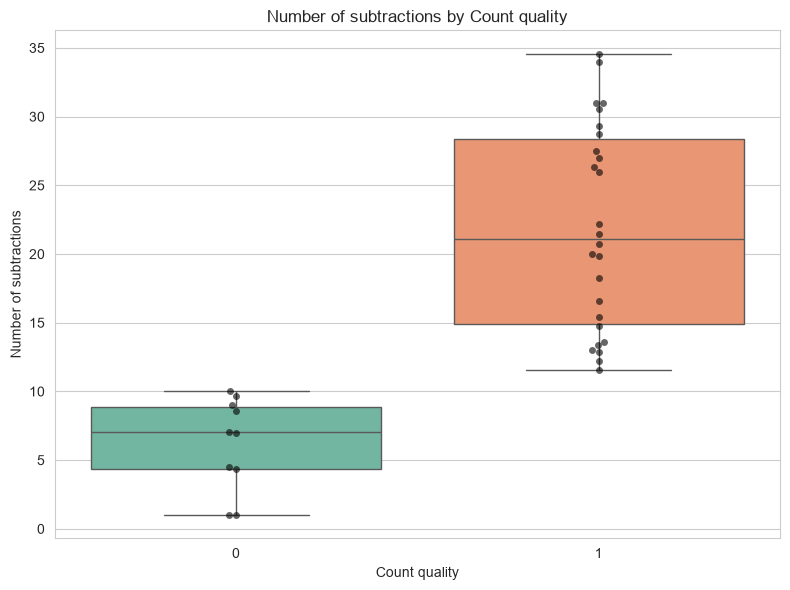

In [7]:
from eegmat.plots import boxplot_subtractions
fig = boxplot_subtractions(info, group_col='Count quality', value_col='Number of subtractions', invert=False)
fig

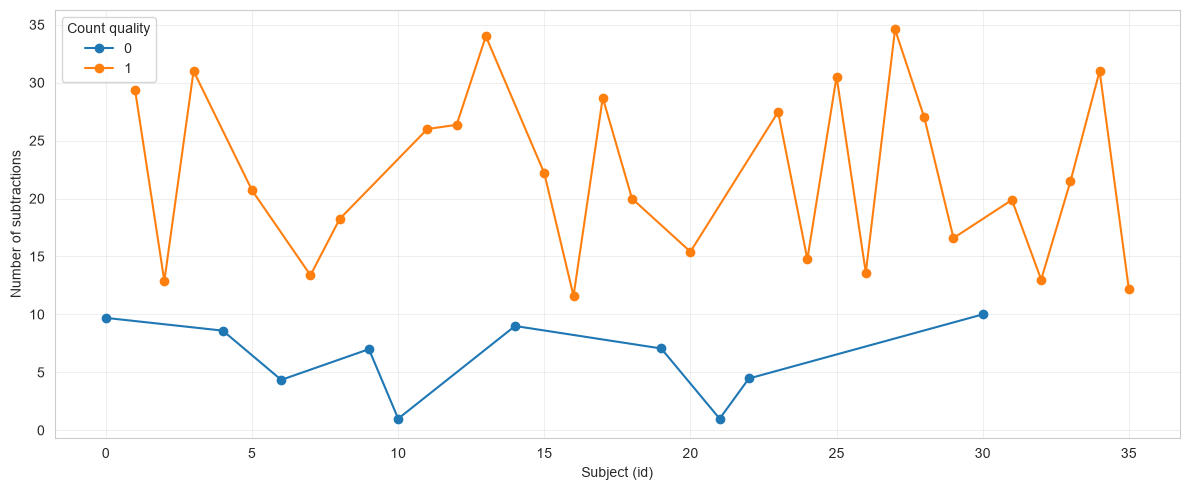

In [8]:
from eegmat.plots import snake_plot_subtractions
fig = snake_plot_subtractions(info, subject_col='Subject', value_col='Number of subtractions', group_col='Count quality')
fig

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=group_col, y=value_col, data=df, palette=palette, order=order, inner=None, cut=0)


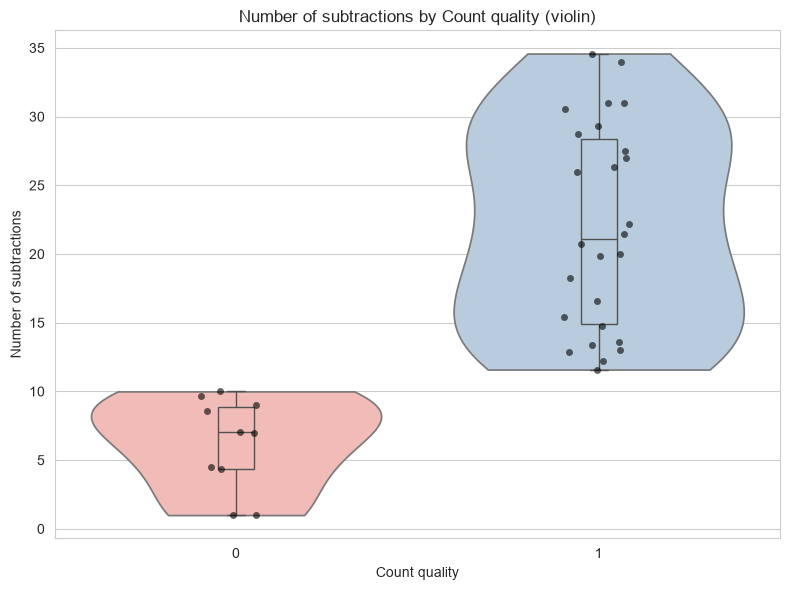

In [9]:
from eegmat.plots import violin_subtractions
fig = violin_subtractions(info, group_col='Count quality', value_col='Number of subtractions')
fig

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=group_col, y=value_col, data=df, palette=palette, order=order, inner=None, cut=0)


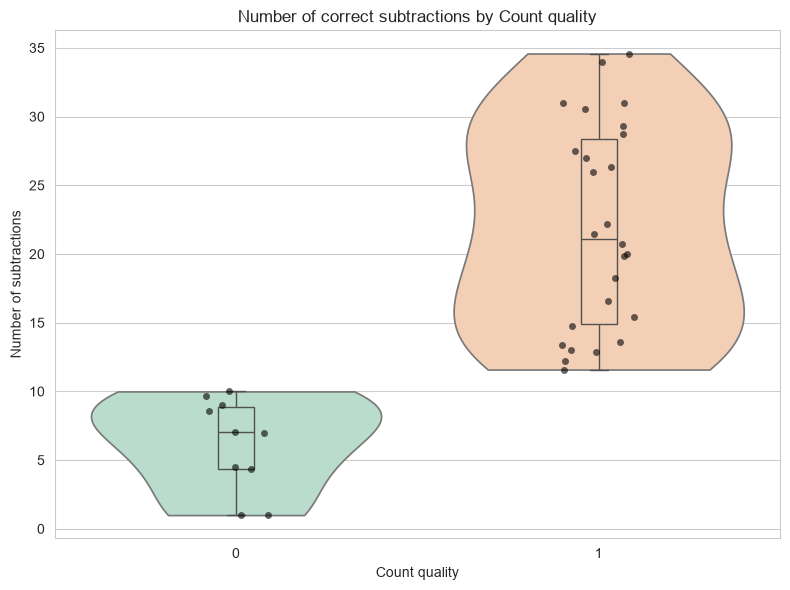

In [10]:
from eegmat.plots import violin_subtractions
fig = violin_subtractions(info,
                          group_col='Count quality',
                          value_col='Number of subtractions',
                          palette='Pastel2',
                          order=None,
                          show_box=True,
                          title='Number of correct subtractions by Count quality')
fig

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:128: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(x=group_col, y=value_col, data=df, palette=palette)


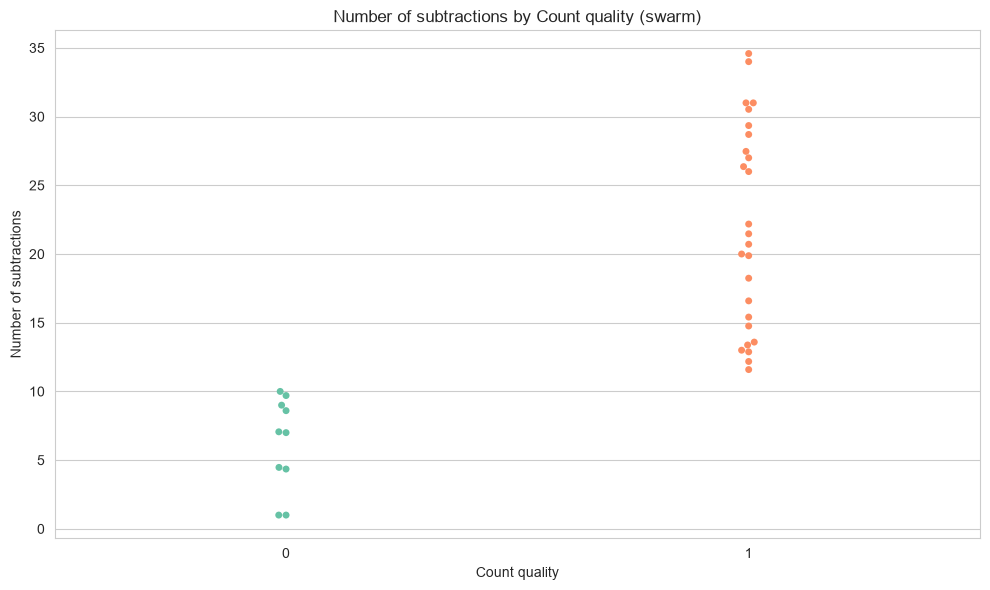

In [11]:
from eegmat.plots import swarm_plot_subtractions
fig = swarm_plot_subtractions(info,
                              group_col='Count quality',
                              value_col='Number of subtractions',
                              palette='Set2')
fig

In [12]:
# Uruchom w komórce notebooka (bez restartu kernela)
import importlib
import eegmat.splits as splits_mod
importlib.reload(splits_mod)
from eegmat.splits import split_subjects, plot_subject_allocation

In [13]:
from eegmat.splits import split_subjects, plot_subject_allocation

# standardowy przypadek
subs = [f'Subject{str(i).zfill(2)}' for i in range(36)]
assign = split_subjects(subs, spec={'train':0.6,'val':0.2,'dev':0.1,'holdout':0.1}, random_state=0)
print({k: len(v) for k,v in assign.items()})

# mała liczba subjectów — wymuszamy min_size=1
subs2 = [f'Subject{str(i).zfill(2)}' for i in range(6)]
assign2 = split_subjects(subs2, spec={'train':0.6,'val':0.2,'dev':0.1,'holdout':0.1}, random_state=1, min_size=1)
print({k: len(v) for k,v in assign2.items()})

# spec z bezwzględnymi liczbami
assign3 = split_subjects(subs2, spec={'train':3,'val':1,'dev':1,'holdout':1}, random_state=1)
print({k: len(v) for k,v in assign3.items()})

# narysuj alokację
fig = plot_subject_allocation(assign)

{'train': 21, 'val': 7, 'dev': 4, 'holdout': 4}
{'train': 3, 'val': 1, 'dev': 1, 'holdout': 1}
{'train': 3, 'val': 1, 'dev': 1, 'holdout': 1}


/Users/gsk/documents/projects/in-ynierka/eegmat/splits.py:318: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


In [14]:
subs2 = [f'Subject{str(i).zfill(2)}' for i in range(6)]
assign2 = split_subjects(subs2, spec={'train':0.6,'val':0.2,'dev':0.1,'holdout':0.1}, random_state=1, min_size=1)
print({k: len(v) for k,v in assign2.items()})

{'train': 3, 'val': 1, 'dev': 1, 'holdout': 1}


In [15]:
import importlib
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import distribution_plot, distribution_by_assignments

info_df rows: 10


,Subject,Number of subtractions
0,Subject00,3
1,Subject01,1
2,Subject02,7
3,Subject03,2
4,Subject04,2


{'train': 6, 'val': 2, 'dev': 1, 'holdout': 1}


/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:202: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(sub[value_col].dropna(), label=label, color=colors[i], fill=fill)
/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:202: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(sub[value_col].dropna(), label=label, color=colors[i], fill=fill)


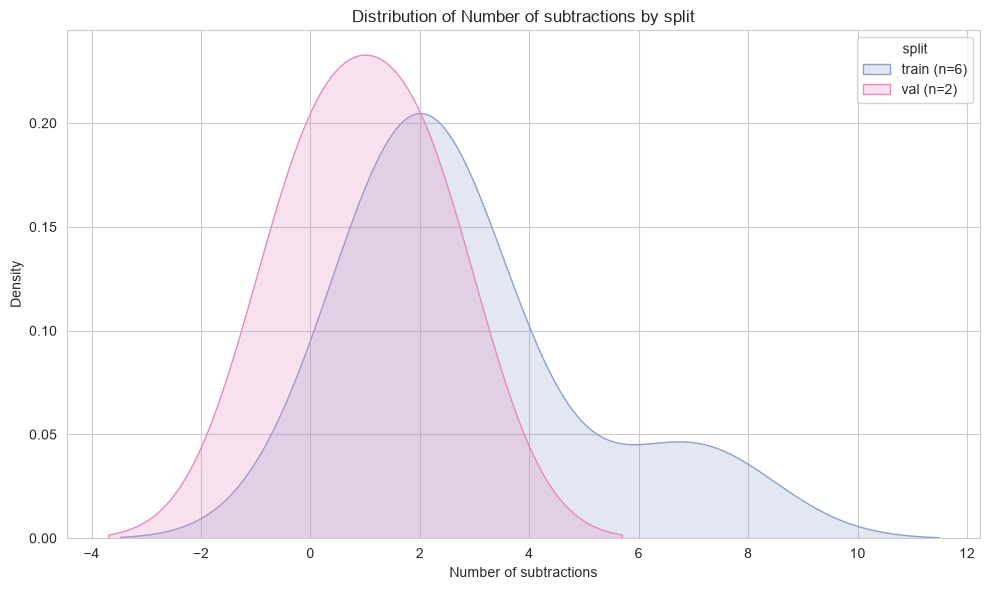

In [16]:
# Wklej do notebooka i uruchom
import importlib, os
import pandas as pd
import numpy as np

import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import distribution_plot, distribution_by_assignments

# Przygotuj info_df jeśli jeszcze nie istnieje:
if 'info_df' not in globals():
    # 1) spróbuj wczytać CSV jeśli istnieje
    for path in ('subject-info.csv', 'datasets/subject-info.csv'):
        if os.path.exists(path):
            info_df = pd.read_csv(path)
            break
    else:
        # 2) fallback: spróbuj zebrać subjecty z eegmat (jeśli zainstalowane), inaczej demo
        try:
            from eegmat.io import load_all
            recs = load_all()
            # recs keys are (subject, state) tuples -> pobierz unikalne subjecty
            subs = sorted({f'Subject{int(k[0]):02d}' for k in recs.keys()})
        except Exception:
            subs = [f'Subject{str(i).zfill(2)}' for i in range(10)]
        # demo kolumna 'Number of subtractions' (zamień na realne dane jeśli masz)
        info_df = pd.DataFrame({
            'Subject': subs,
            'Number of subtractions': np.random.poisson(2, len(subs))
        })

print('info_df rows:', len(info_df))
display(info_df.head())

# Przygotuj assignments jeśli brak:
if 'assignments' not in globals():
    try:
        from eegmat.splits import split_subjects
        assignments = split_subjects(info_df['Subject'].tolist(),
                                     spec={'train':0.6,'val':0.2,'dev':0.1,'holdout':0.1},
                                     random_state=0, min_size=1)
    except Exception as e:
        # prosty równy podział jako fallback
        subs = info_df['Subject'].tolist()
        n = len(subs)
        assignments = {
            'train': subs[:int(n*0.6)],
            'val': subs[int(n*0.6):int(n*0.8)],
            'dev': subs[int(n*0.8):int(n*0.9)],
            'holdout': subs[int(n*0.9):]
        }

print({k: len(v) for k,v in assignments.items()})

# Rysuj: pojedynczy rozkład + rozkłady per-split
distribution_plot(info_df, value_col='Number of subtractions', kind='kde')
distribution_by_assignments(info_df, assignments, subject_col='Subject', value_col='Number of subtractions', kind='kde')


/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:280: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='split', y=value_col, data=merged, palette=palette, inner='quartile')


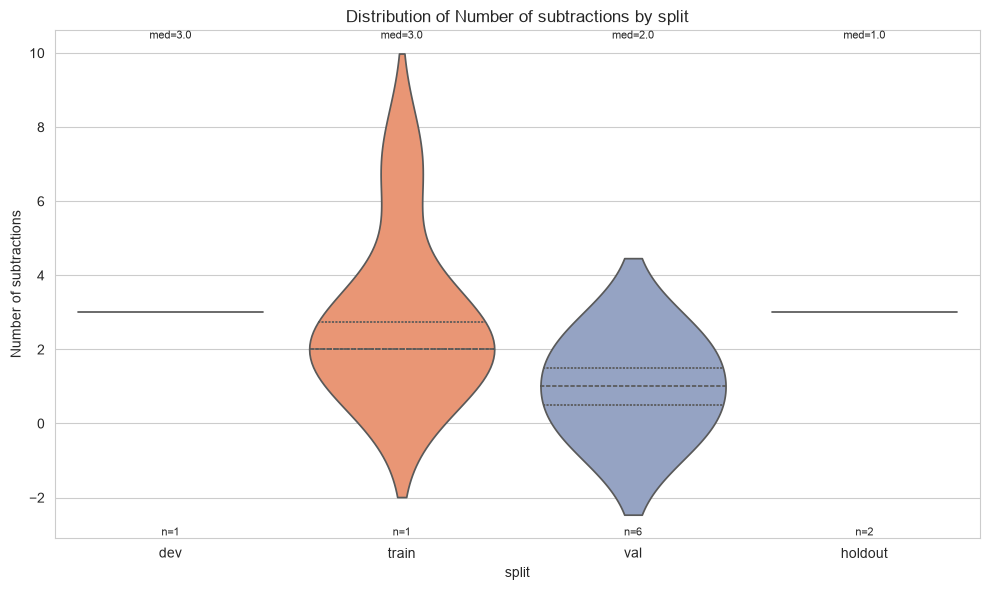

In [17]:
import importlib
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import distribution_plot, distribution_by_assignments

distribution_plot(info_df, value_col='Number of subtractions', kind='kde')
distribution_by_assignments(info_df, assignments, subject_col='Subject', value_col='Number of subtractions', kind='violin')

In [18]:
import importlib
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import distribution_by_assignments

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:278: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='split', y=value_col, data=merged, palette=palette)


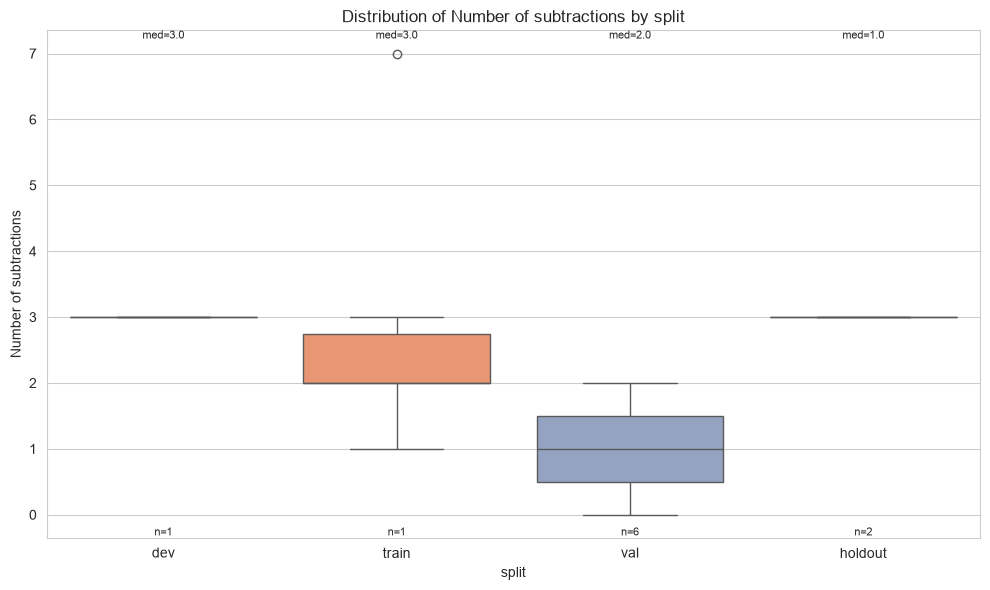

In [19]:
distribution_by_assignments(info_df, assignments, subject_col='Subject', value_col='Number of subtractions')

In [20]:
# Przeładuj moduł bez restartu kernela
import importlib
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import quantity_quality_plot

/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:359: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=quality_col, y=quantity_col, data=df, palette=palette, ax=ax1)
/Users/gsk/documents/projects/in-ynierka/eegmat/plots.py:365: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


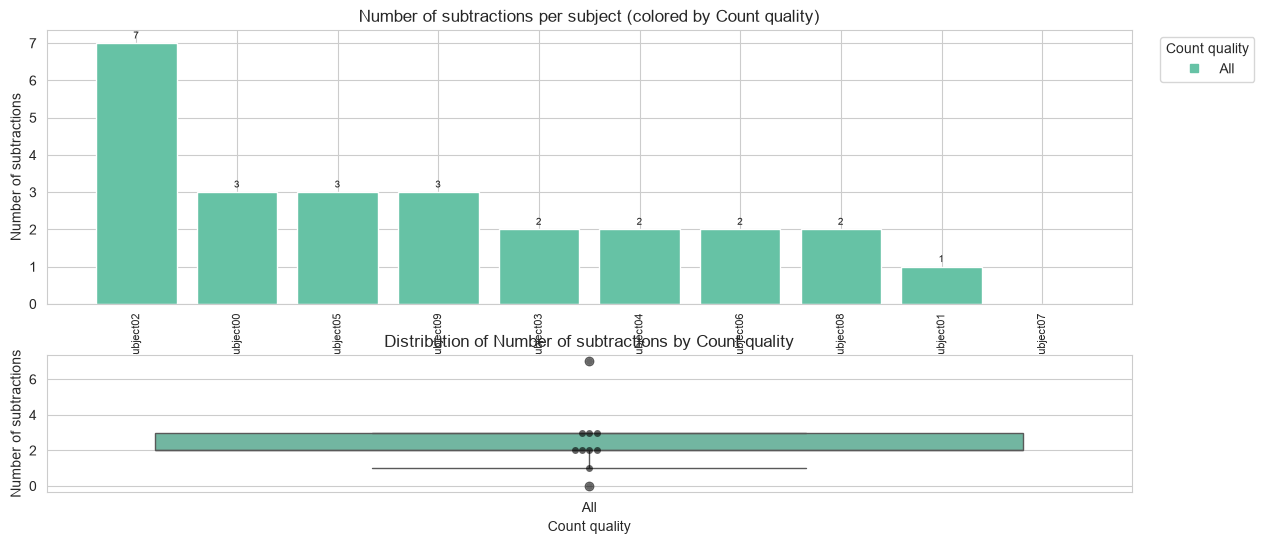

In [21]:
from eegmat.plots import quantity_quality_plot
fig = quantity_quality_plot(info_df,
                            subject_col='Subject',
                            quantity_col='Number of subtractions',
                            quality_col='Count quality')
fig

In [ ]:
# Diagnostic + safe call for correct/incorrect plot
import importlib, re
from IPython.display import display
import pandas as pd
import eegmat.plots as plots_mod
importlib.reload(plots_mod)
from eegmat.plots import correct_incorrect_ratio_plot, quantity_quality_plot

def _find_subject_col(df):
    for c in df.columns:
        if 'subject' in c.lower():
            return c
    return df.columns[0] if len(df.columns) else None

def _find_col_by_candidates(df, candidates):
    cols = list(df.columns)
    lc = [c.lower() for c in cols]
    # direct substring match
    for cand in candidates:
        cand = cand.lower()
        for i, col in enumerate(lc):
            if cand in col:
                return cols[i]
    # looser normalized match
    norm = [''.join(re.findall(r'[a-z0-9]+', x.lower())) for x in cols]
    for cand in candidates:
        nc = ''.join(re.findall(r'[a-z0-9]+', cand.lower()))
        for i, col in enumerate(norm):
            if nc and nc in col:
                return cols[i]
    return None

def _try_total_minus_correct(df, subject_col, corr_col):
    total_candidates = ['total','n_total','n_subtractions','num_subtractions','numberofsubtractions','number of subtractions','n_subs','count']
    total_col = _find_col_by_candidates(df, total_candidates)
    if total_col:
        tmp = df[[subject_col, corr_col, total_col]].copy()
        tmp = tmp.rename(columns={corr_col: 'correct', total_col: 'total'})
        tmp['incorrect'] = tmp['total'] - tmp['correct']
        return tmp[[subject_col, 'correct', 'incorrect']]
    return None

# Start diagnostics
print('--- DIAGNOSTICS ---\n')

# info_df
if 'info_df' in globals() and isinstance(info_df, pd.DataFrame):
    print('info_df columns:', list(info_df.columns))
    display(info_df.head(5))
else:
    print('No info_df found or it is empty.')

print('\n')

# subtractions_df
if 'subtractions_df' in globals() and isinstance(subtractions_df, pd.DataFrame):
    print('subtractions_df columns:', list(subtractions_df.columns))
    display(subtractions_df.head(5))
else:
    print('No subtractions_df found.')

print('\n--- ATTEMPTING AUTO-DETECTION ---\n')

# Try aggregated mode first
if 'info_df' in globals() and isinstance(info_df, pd.DataFrame) and not info_df.empty:
    df = info_df
    subject_col = _find_subject_col(df)
    corr_candidates = ['n_correct','num_correct','correct','n_corr','ncorrect','correct_count','n_success','success','true','ok','good']
    incorr_candidates = ['n_incorrect','num_incorrect','incorrect','n_wrong','wrong','fail','false','bad','n_error','errors']
    corr_col = _find_col_by_candidates(df, corr_candidates)
    incorr_col = _find_col_by_candidates(df, incorr_candidates)
    print('Detected subject_col =', subject_col)
    print('Detected candidate correct column =', corr_col)
    print('Detected candidate incorrect column =', incorr_col)

    if corr_col and incorr_col:
        print('Calling plot with detected aggregated columns...')
        fig = correct_incorrect_ratio_plot(df, subject_col=subject_col,
                                           correct_col=corr_col, incorrect_col=incorr_col,
                                           normalize=True, kind='stacked', annotate=True)
        display(fig)
    elif corr_col and not incorr_col:
        print('Found correct-like column but no incorrect-like column. Trying to derive incorrect = total - correct...')
        derived = _try_total_minus_correct(df, subject_col, corr_col)
        if derived is not None:
            display(derived.head(6))
            print('Derived counts found, calling plot...')
            fig = correct_incorrect_ratio_plot(derived, subject_col=subject_col,
                                               correct_col='correct', incorrect_col='incorrect',
                                               normalize=True, kind='stacked', annotate=True)
            display(fig)
        else:
            print('Could not derive incorrect. Available columns:', list(df.columns))
            raise RuntimeError('Provide both aggregated columns (correct/incorrect) in `info_df`, or provide `subtractions_df`.')
    elif incorr_col and not corr_col:
        print('Found incorrect-like column but no correct-like column. Trying to derive correct = total - incorrect...')
        derived = _try_total_minus_correct(df, subject_col, incorr_col)
        if derived is not None:
            display(derived.head(6))
            print('Derived counts found, calling plot...')
            fig = correct_incorrect_ratio_plot(derived, subject_col=subject_col,
                                               correct_col='correct', incorrect_col='incorrect',
                                               normalize=True, kind='stacked', annotate=True)
            display(fig)
        else:
            print('Could not derive correct. Available columns:', list(df.columns))
            raise RuntimeError('Provide both aggregated columns (correct/incorrect) in `info_df`, or provide `subtractions_df`.')
    else:
        print('No correct/incorrect-like columns detected in info_df.')
        # fall through to try long mode below

# Try long mode if present
if 'subtractions_df' in globals() and isinstance(subtractions_df, pd.DataFrame) and not subtractions_df.empty:
    s = subtractions_df
    subj_col_long = _find_subject_col(s)
    flag_candidates = ['correct','is_correct','success','ok','accepted','label_correct','true','quality','status']
    flag_col = _find_col_by_candidates(s, flag_candidates)
    print('Long table detected. subject_col =', subj_col_long)
    print('Detected candidate correctness/quality column =', flag_col)
    if flag_col:
        print('Calling plot using long subtractions_df and flag_col =', flag_col)
        fig = correct_incorrect_ratio_plot(None, subject_col=subj_col_long, subtractions_df=s, correct_flag_col=flag_col, kind='stacked', normalize=True, annotate=True)
        display(fig)
    else:
        print('No correctness-like column detected in subtractions_df. Available columns:', list(s.columns))
        raise RuntimeError('Provide a correctness column (0/1 or boolean) in `subtractions_df`, or aggregated counts in `info_df`.')

# If we reached here without plotting, give final actionable message
if not ('info_df' in globals() and isinstance(info_df, pd.DataFrame) and (
        (_find_col_by_candidates(info_df, ['correct','n_correct','num_correct']) and _find_col_by_candidates(info_df, ['incorrect','n_incorrect','num_incorrect'])) or
        _find_col_by_candidates(info_df, ['total','n_subtractions','num_subtractions']))) and not ('subtractions_df' in globals() and isinstance(subtractions_df, pd.DataFrame)):
    print('\\nACTIONABLE: To produce the correct/incorrect plot, do one of the following:\\n'
          '- In `info_df` provide two columns with per-subject counts, e.g. `n_correct` and `n_incorrect` (or `total` + `n_correct`).\\n'
          '- OR provide `subtractions_df` (one row per subtraction) containing a subject column and a correctness flag column (0/1 or boolean) such as `correct` or `is_correct`.\\n'
          'If you want, paste here the output of `list(info_df.columns)` and `list(subtractions_df.columns)` and I will tell the exact names to pass.')